# Etapa 2 — nosso otimizador de dieta × otimizador do RuFaS

## Propósito

Construir uma dieta de menor custo com um **otimizador desenvolvido**, aplicar essa dieta ao RuFaS como uma ração fixa e comparar o resultado com a dieta produzida pelo **formulador interno do RuFaS**. Os dois métodos usam o mesmo rebanho, a mesma semente, os mesmos ingredientes e os mesmos preços.

## Como a comparação é feita

- **Nosso otimizador:** programação linear com somente as cinco restrições mínimas do PDF compartilhado pelo professor. Os pisos são derivados do fornecimento da dieta NASEM de referência; depois, o RuFaS recebe nossa solução como dieta fixa.
- **Otimizador do RuFaS:** recebe os mesmos ingredientes e preços com o modo `rufas_min_cost`; o RuFaS escolhe as quantidades usando SLSQP e requisitos NASEM calculados para os animais.
- **Avaliação comum:** ambas as dietas são simuladas pelo RuFaS, permitindo comparar composição, produção de leite, custo e margem.

## De onde vêm os valores mínimos do nosso modelo?

Antes da primeira execução, nosso código possui as variáveis de decisão, os preços, a composição nutricional dos ingredientes, a função objetivo e a estrutura das cinco desigualdades. Ele ainda **não possui os cinco valores numéricos mínimos**.

O fluxo adotado é:

1. o RuFaS formula primeiro uma dieta usando seu modelo completo NASEM;
2. o projeto lê as quantidades médias dessa dieta;
3. usando a biblioteca nutricional, calcula quanto ela fornece de TDN, proteína bruta, cálcio, fósforo e NDF;
4. esses cinco fornecimentos tornam-se os pisos do nosso problema linear;
5. nosso otimizador procura outra combinação de menor custo que forneça pelo menos os mesmos cinco valores;
6. a solução é devolvida ao RuFaS como dieta fixa para avaliação.

> **Precisão metodológica:** não extraímos diretamente as exigências internas brutas do NASEM. Usamos como referência os fornecimentos lineares da dieta encontrada pelo RuFaS. As outras condições usadas pelo RuFaS — como consumo, gordura, limites máximos e NDF de forragem — não são transferidas para nosso otimizador.

## Independência

Este notebook pode ser executado sem abrir a Etapa 1. A dependência entre os notebooks é conceitual, não de execução: a Etapa 1 ensina a simular dietas fixas; esta etapa cria e compara dois métodos de otimização.

## Índice

1. **Preparação do ambiente** — carrega bibliotecas, caminhos e formatação.
2. **Cenário, ingredientes e preços** — define a fazenda e aplica um snapshot datado de preços.
3. **Referência RuFaS/NASEM** — gera a fazenda, apresenta a população animal e calcula uma dieta nutricionalmente viável.
4. **Modelo principal** — deriva e aplica somente energia, proteína, cálcio, fósforo e fibra mínimas.
5. **Preparação da nossa dieta** — desativa o formulador do RuFaS para avaliar nossa solução fixa.
6. **Validação das entradas** — confere a estrutura e as cinco restrições.
7. **Avaliação no RuFaS** — simula nossa dieta sob a mesma população aleatória.
8. **Comparação das dietas** — confronta quantidades, percentuais e custo por vaca.
9. **Comparação produtiva e econômica** — compara leite, custo, receita e margem.
10. **Conclusão e limites** — interpreta corretamente o que foi demonstrado.

## 1. Preparação do ambiente

**O que faz:** importa as classes do projeto, define onde estão a fila, o snapshot de preços e a biblioteca nutricional do RuFaS, além de criar a formatação das tabelas.

**Resultado desta etapa:** ambiente pronto para configurar, otimizar, simular e comparar sem depender das variáveis de outro notebook.

In [14]:
# BLOCO 1 — Biblioteca padrão e ferramentas de tabelas e gráficos
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# BLOCO 2 — Componentes desenvolvidos no projeto
from rufas_project import (
    DietConfig, DietIngredient, EconomicConfig, HerdConfig, MilkConfig,
    ParityFractions, SimulationConfig, apply_price_snapshot,
    build_fixed_scenario_from_solution, build_min_cost_scenario,
    calculate_economics, compare_scenarios, derive_main_requirements_from_ration,
    describe_custom_constraints, describe_custom_min_cost_problem,
    describe_min_cost_problem, describe_price_snapshot, load_price_snapshot,
    load_result, save_custom_baseline_artifact, solve_custom_min_cost, submit_simulation,
    summarize_lactating_ration, validate_simulation_config,
    wait_for_simulation,
)

# BLOCO 3 — Caminhos usados dentro do contêiner
SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))
PRICE_SNAPSHOT_PATH = Path('/workspace/configs/market_price_snapshot.json')
FEED_LIBRARY_CANDIDATES = [
    Path('/workspace/data/NASEM_Comp_with_TDN.csv'),
    Path('../RuFaS/input/data/feed/NASEM_Comp_with_TDN.csv'),
]
FEED_LIBRARY_PATH = next((path for path in FEED_LIBRARY_CANDIDATES if path.exists()), None)
if FEED_LIBRARY_PATH is None:
    raise FileNotFoundError('Biblioteca nutricional do RuFaS não encontrada. Reconstrua o contêiner do notebook.')

# BLOCO 4 — Padrão visual reutilizado nas tabelas
TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

def show_table(frame, caption, hide_index=True, formatter=None):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    if formatter:
        styled = styled.format(formatter)
    display(styled)

def format_pt_br(value, decimals=2, suffix=''):
    if pd.isna(value):
        return '—'
    formatted = f'{value:,.{decimals}f}'.replace(',', 'TEMP').replace('.', ',').replace('TEMP', '.')
    return f'{formatted}{suffix}'

print(f'Fila compartilhada: {SHARED_ROOT}')
print(f'Biblioteca nutricional: {FEED_LIBRARY_PATH}')

Fila compartilhada: /workspace/shared
Biblioteca nutricional: /workspace/data/NASEM_Comp_with_TDN.csv


## 2. Cenário, ingredientes e preços

**O que faz:** configura fazenda, rebanho e ingredientes candidatos. Em seguida, aplica um snapshot local com as faixas de preços em reais pesquisadas pelo usuário. Para cada ingrediente, adota o ponto médio da faixa e converte pela PTAX para **USD/kg de matéria seca**. Quando o preço foi informado na matéria natural, ele também é dividido pela fração de matéria seca cadastrada no RuFaS.

**Resultado desta etapa:** os dois otimizadores recebem exatamente o mesmo vetor de preços normalizados. Não são adicionados frete, armazenamento ou perdas, pois o escopo é exclusivamente a formulação da dieta. Os valores representam uma premissa reproduzível do experimento, e não uma cotação de compra válida para todas as regiões.

In [15]:
# BLOCO 1 — Cenário-base; os percentuais servem apenas como cadastro inicial
base = SimulationConfig(
    name='fase2_base_com_precos_pesquisados',
    simulation_days=30,
    random_seed=100,
    herd=HerdConfig(
        cow_num=20, milking_cow_fraction=0.80, breed='HO',
        parity_fractions=ParityFractions(0.40, 0.25, 0.20, 0.10, 0.05),
    ),
    milk=MilkConfig(fat_percent=4.0, protein_percent=3.2, mature_body_weight_kg=740.1),
    diet=DietConfig(
        mode='fixed', formulation_interval_days=30,
        # Argumentos: ID, participação inicial (%), preço (USD/kg MS), nome.
        # Os preços abaixo coincidem com o snapshot e são reaplicados por ele no BLOCO 3.
        ingredients=[
            DietIngredient(23, 0.74, 1.81415600, 'Blood meal, low dRUP'),
            DietIngredient(44, 15.31, 0.27297661, 'Corn grain dry, medium grind'),
            DietIngredient(50, 37.45, 0.12094373, 'Corn silage, immature'),
            DietIngredient(104, 0.37, 0.17027486, 'Grass/legume mix, legume silage'),
            DietIngredient(110, 17.65, 0.20610022, 'Legume silage, mid-maturity'),
            DietIngredient(301, 3.27, 1.12247177, 'Farm ES Mineral Mix'),
            DietIngredient(302, 25.21, 0.28438438, 'Farm ES Midwest BP Blend'),
        ],
    ),
    economics=EconomicConfig(currency='USD'),
)

# BLOCO 2 — Traduções usadas somente na apresentação
names_pt = {
    23: 'Farinha de sangue, baixo teor de dRUP',
    44: 'Grão de milho seco, moagem média',
    50: 'Silagem de milho imatura',
    104: 'Mistura de gramínea e leguminosa ensilada',
    110: 'Silagem de leguminosa em maturação intermediária',
    301: 'Mistura mineral da fazenda (ES)',
    302: 'Mistura de subprodutos do Meio-Oeste (BP)',
}

# BLOCO 3 — Leitura e aplicação do snapshot reproduzível
price_snapshot = load_price_snapshot(PRICE_SNAPSHOT_PATH)
reference = apply_price_snapshot(base, price_snapshot)
price_table = describe_price_snapshot(price_snapshot)
price_table['Ingrediente'] = price_table['feed_type'].map(names_pt)
price_table['Tipo da fonte'] = price_table['source_kind'].map({
    'user_research': 'Pesquisa fornecida pelo usuário',
})
price_table['Base do preço'] = price_table['price_basis'].map({
    'dry_matter': 'Matéria seca',
    'as_fed': 'Matéria natural',
})
price_display = price_table.rename(columns={
    'feed_type': 'ID',
    'range_min_brl_per_kg': 'Mínimo (BRL/kg)',
    'range_max_brl_per_kg': 'Máximo (BRL/kg)',
    'raw_price': 'Ponto médio (BRL/kg)', 'raw_unit': 'Unidade original',
    'dry_matter_fraction': 'Fração de MS',
    'price_usd_per_kg_dm': 'Preço normalizado (USD/kg MS)',
    'source_name': 'Fonte', 'reference_date': 'Data de referência',
})[['ID', 'Ingrediente', 'Mínimo (BRL/kg)', 'Máximo (BRL/kg)',
    'Ponto médio (BRL/kg)', 'Base do preço', 'Fração de MS',
    'Preço normalizado (USD/kg MS)', 'Tipo da fonte', 'Fonte', 'Data de referência']]
show_table(
    price_display, 'Preços e proveniência dos ingredientes',
    formatter={
        'Mínimo (BRL/kg)': lambda value: format_pt_br(value, 2),
        'Máximo (BRL/kg)': lambda value: format_pt_br(value, 2),
        'Ponto médio (BRL/kg)': lambda value: format_pt_br(value, 3),
        'Fração de MS': lambda value: format_pt_br(value, 4),
        'Preço normalizado (USD/kg MS)': lambda value: format_pt_br(value, 4),
    },
)

# BLOCO 4 — Taxa de câmbio e regra utilizadas para tornar a conversão auditável
exchange = price_snapshot['exchange_rate']
exchange_table = pd.DataFrame([
    ('Taxa de câmbio', f"1 USD = {exchange['brl_per_usd']:.4f} BRL"),
    ('Tipo da taxa', exchange['rate_type']),
    ('Data da taxa', exchange['reference_date']),
    ('Fonte cambial', exchange['source_name']),
    ('Regra de seleção', price_snapshot['selection_rule']),
], columns=['Parâmetro', 'Valor'])
show_table(exchange_table, 'Conversão cambial e regra adotada')

ID,Ingrediente,Mínimo (BRL/kg),Máximo (BRL/kg),Ponto médio (BRL/kg),Base do preço,Fração de MS,Preço normalizado (USD/kg MS),Tipo da fonte,Fonte,Data de referência
23,"Farinha de sangue, baixo teor de dRUP","9,00","10,50","9,750",Matéria seca,"0,9086","1,8142",Pesquisa fornecida pelo usuário,Pesquisa fornecida pelo usuário; referência internacional USDA,2026-10-29
44,"Grão de milho seco, moagem média","1,10","1,45","1,275",Matéria natural,"0,8691","0,2730",Pesquisa fornecida pelo usuário,Pesquisa fornecida pelo usuário; referência World Bank e mercado interno,2026-10-29
50,Silagem de milho imatura,"0,50","0,80","0,650",Matéria seca,"0,3127","0,1209",Pesquisa fornecida pelo usuário,Pesquisa de mercado fornecida pelo usuário,2026-10-29
104,Mistura de gramínea e leguminosa ensilada,"0,25","0,50","0,375",Matéria natural,"0,4098","0,1703",Pesquisa fornecida pelo usuário,Pesquisa de mercado fornecida pelo usuário,2026-10-29
110,Silagem de leguminosa em maturação intermediária,"0,35","0,60","0,475",Matéria natural,"0,4288","0,2061",Pesquisa fornecida pelo usuário,Pesquisa de mercado fornecida pelo usuário,2026-10-29
301,Mistura mineral da fazenda (ES),"4,50","7,50","6,000",Matéria natural,"0,9946","1,1225",Pesquisa fornecida pelo usuário,Pesquisa de mercado fornecida pelo usuário,2026-10-29
302,Mistura de subprodutos do Meio-Oeste (BP),"0,80","1,30","1,050",Matéria natural,"0,6870","0,2844",Pesquisa fornecida pelo usuário,Pesquisa de mercado fornecida pelo usuário,2026-10-29


Parâmetro,Valor
Taxa de câmbio,1 USD = 5.3744 BRL
Tipo da taxa,PTAX de venda
Data da taxa,2026-10-29
Fonte cambial,Banco Central do Brasil — PTAX
Regra de seleção,Ponto médio da faixa em BRL fornecida pelo usuário; preços na matéria natural são divididos pela fração de matéria seca e pela PTAX


In [16]:
# BLOCO 1 — Conferência separada do preço de referência do leite
milk_snapshot = price_snapshot['milk']
milk_inputs = pd.DataFrame([
    ('Preço publicado', f"{milk_snapshot['raw_price']:.2f} {milk_snapshot['raw_unit']}"),
    ('Preço normalizado', f"{reference.economics.milk_price_per_kg:.4f} USD/kg"),
    ('Equivalente por litro', f"{milk_snapshot['equivalent_usd_per_liter']:.4f} USD/L"),
    ('Densidade adotada', f"{reference.economics.milk_density_kg_per_liter:.3f} kg/L"),
    ('Fonte', milk_snapshot['source_name']),
    ('Data de referência', milk_snapshot['reference_date']),
], columns=['Parâmetro econômico', 'Valor'])
show_table(milk_inputs, 'Preço do leite usado na avaliação econômica')

Parâmetro econômico,Valor
Preço publicado,19.70 USD/cwt
Preço normalizado,0.4343 USD/kg
Equivalente por litro,0.4473 USD/L
Densidade adotada,1.030 kg/L
Fonte,"USDA NASS Agricultural Prices — All Milk, United States, March 2026"
Data de referência,2026-03-01


## 3. Dieta de referência calculada pelo RuFaS/NASEM

**O que faz:** executa primeiro o formulador interno do RuFaS. Essa solução atende ao conjunto completo de condições NASEM usado pelo simulador e fornece a referência para os cinco indicadores lineares citados no PDF.

**Resultado desta etapa:** uma fazenda com população animal efetivamente gerada e uma dieta NASEM real, calculada pelo RuFaS. O projeto não recebe uma tabela pronta de mínimos: ele usa as quantidades dessa dieta e os coeficientes da biblioteca nutricional para calcular seus cinco fornecimentos lineares.

In [17]:
# BLOCO 1 — Cenário que ativa o formulador interno do RuFaS
rufas_scenario = build_min_cost_scenario(reference, name='fase2_otimizador_rufas')
validate_simulation_config(rufas_scenario)
show_table(describe_min_cost_problem(rufas_scenario), 'Problema executado pelo RuFaS/NASEM')

# BLOCO 2 — Execução da dieta NASEM de referência
rufas_job = submit_simulation(rufas_scenario, SHARED_ROOT)
wait_for_simulation(rufas_job, SHARED_ROOT, timeout_seconds=1800)
rufas_result = load_result(rufas_job, SHARED_ROOT)
rufas_ration, rufas_totals = summarize_lactating_ration(rufas_result, rufas_scenario)
print('Dieta de referência do RuFaS/NASEM concluída.')

Elemento,Definição
Variáveis de decisão,xᵢ = kg de matéria seca do ingrediente i por vaca e por dia
Função objetivo,min C(x) = Σ pᵢ × xᵢ
Preço,pᵢ = USD por kg de matéria seca do ingrediente i
Método numérico,"SLSQP, executado pelo formulador interno do RuFaS"
Padrão nutricional,NASEM
Restrições,"Energia líquida, proteína, cálcio, fósforo, NDF, NDF de forragem, gordura e consumo de matéria seca"
Ingredientes candidatos,7 ingredientes informados no notebook
Critério de comparação,"Custo alimentar, produção de leite, receita e margem sobre alimentação"


Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados
Dieta de referência do RuFaS/NASEM concluída.


### 3.1 População inicial da fazenda gerada pelo RuFaS

**O que faz:** apresenta o rebanho efetivamente criado pelo RuFaS antes do primeiro dia da simulação de referência. A configuração informa o número de vacas adultas e as proporções; o RuFaS também gera bezerras e novilhas necessárias à dinâmica da fazenda.

**Por que é importante:** confirma sobre quais animais a dieta de referência foi calculada. Como os dois cenários usam a mesma configuração e a mesma semente, a avaliação da nossa dieta reproduz essa população inicial.

In [18]:
# BLOCO 1 — População efetivamente gerada na execução de referência
initial_population = rufas_result['initial_population']

# BLOCO 2 — Formatação de valores ausentes, números e unidades
def format_initial_value(value, decimals=0, unit=''):
    if value is None:
        return 'Não informado pelo RuFaS'
    suffix = f' {unit}' if unit else ''
    return format_pt_br(value, decimals, suffix)

# BLOCO 3 — Tradução e limpeza da raça informada pelo relatório
breed_names = {'HO': 'Holandesa', 'Holstein': 'Holandesa', 'JE': 'Jersey', 'Jersey': 'Jersey'}
breed_raw = initial_population['breed']
breed_value = str(breed_raw).strip().strip('{}[]()').replace(chr(39), '').replace(chr(34), '').strip() if breed_raw else None
breed_description = breed_names.get(breed_value, breed_value or 'Não informada')
breed_display = f'{breed_description} ({breed_value})' if breed_value and breed_description != breed_value else breed_description

# BLOCO 4 — Total da fazenda: bezerras + três grupos de novilhas + vacas
stage_keys = [
    'number_of_calves', 'number_of_heifer_is', 'number_of_heifer_iis',
    'number_of_heifer_iiis', 'number_of_cows',
]
stage_values = [initial_population[key] for key in stage_keys]
reported_stage_values = [value for value in stage_values if value is not None]
total_animals = sum(reported_stage_values) if reported_stage_values else None

# BLOCO 5 — Resumo da fazenda sorteada pela semente
initial_summary = pd.DataFrame([
    ('Semente aleatória utilizada', str(initial_population['random_seed']) if initial_population['random_seed'] is not None else 'Não informada'),
    ('Raça', breed_display),
    ('Total de animais', format_initial_value(total_animals, unit='animais')),
    ('Bezerras', format_initial_value(initial_population['number_of_calves'], unit='animais')),
    ('Novilhas I', format_initial_value(initial_population['number_of_heifer_is'], unit='animais')),
    ('Novilhas II', format_initial_value(initial_population['number_of_heifer_iis'], unit='animais')),
    ('Novilhas III', format_initial_value(initial_population['number_of_heifer_iiis'], unit='animais')),
    ('Vacas', format_initial_value(initial_population['number_of_cows'], unit='animais')),
    ('Vacas em lactação', format_initial_value(initial_population['number_of_lactating_cows'], unit='animais')),
    ('Vacas secas', format_initial_value(initial_population['number_of_dry_cows'], unit='animais')),
    ('Idade média das vacas', format_initial_value(initial_population['average_cow_age_days'], 1, 'dias')),
    ('Peso corporal médio das vacas', format_initial_value(initial_population['average_cow_body_weight_kg'], 1, 'kg')),
    ('Dias em gestação (média)', format_initial_value(initial_population['average_cow_days_in_pregnancy'], 1, 'dias')),
    ('Dias em lactação (média)', format_initial_value(initial_population['average_cow_days_in_milk'], 1, 'dias')),
    ('Número médio de partos', format_initial_value(initial_population['average_cow_parity'], 2)),
], columns=['Característica inicial', 'Valor gerado'])
show_table(initial_summary, 'População inicial efetivamente gerada pelo RuFaS')

# BLOCO 6 — Distribuição das vacas adultas por número de partos
parity_labels = {
    '1': '1º parto', '2': '2º parto', '3': '3º parto',
    '4': '4º parto', '5': '5º parto', '6_or_more': '6 ou mais partos',
}
parity_table = pd.DataFrame([
    (parity_labels[parity], int(quantity))
    for parity, quantity in initial_population['parity_distribution'].items()
    if quantity is not None
], columns=['Grupo de paridade', 'Quantidade de vacas'])
show_table(parity_table, 'Distribuição inicial das vacas por número de partos')

Característica inicial,Valor gerado
Semente aleatória utilizada,100
Raça,Holandesa (Holstein)
Total de animais,114 animais
Bezerras,8 animais
Novilhas I,44 animais
Novilhas II,38 animais
Novilhas III,5 animais
Vacas,19 animais
Vacas em lactação,15 animais
Vacas secas,4 animais


Grupo de paridade,Quantidade de vacas
1º parto,8
2º parto,5
3º parto,4
4º parto,2
5º parto,0
6 ou mais partos,0


## 4. Modelo principal: cinco restrições mínimas

**O que faz:** calcula quanto a dieta NASEM fornece dos cinco nutrientes do PDF e transforma esses valores em pisos do nosso modelo linear. A função objetivo é exclusivamente $\min \sum_i p_i x_i$: minimizar o custo diário da dieta, em que $p_i$ é o preço e $x_i$ é a quantidade do ingrediente. Ela **não maximiza a produção de leite**. O nosso algoritmo recebe os cinco números calculados, e não as demais restrições internas do RuFaS.

**Resultado desta etapa:** dieta própria de menor custo sujeita exclusivamente a energia, proteína, cálcio, fósforo e fibra mínimas. A produção de leite não faz parte da função objetivo nem dessas cinco restrições: ela é observada depois, quando a dieta encontrada é simulada pelo RuFaS. Não há consumo fixo, máximos nutricionais, limites de inclusão, gordura ou NDF de forragem no nosso modelo.

In [19]:
# BLOCO 1 — Extração dos cinco pisos lineares da dieta NASEM
requirements = derive_main_requirements_from_ration(rufas_ration, FEED_LIBRARY_PATH)
show_table(describe_custom_min_cost_problem(reference, requirements), 'Nosso problema de otimização')
show_table(
    describe_custom_constraints(requirements), 'Cinco restrições mínimas do modelo principal',
    formatter={'Mínimo': lambda value: format_pt_br(value, 3)},
)

# BLOCO 2 — Solução independente do nosso problema linear
custom_solution = solve_custom_min_cost(reference, FEED_LIBRARY_PATH, requirements)
if not custom_solution.success:
    raise RuntimeError(f'Nosso problema não encontrou solução viável: {custom_solution.message}')

# BLOCO 3 — Dieta calculada pelo nosso otimizador
custom_ration_display = custom_solution.ration.copy()
custom_ration_display['Ingrediente'] = custom_ration_display['feed_type'].map(names_pt)
custom_ration_display = custom_ration_display.rename(columns={
    'feed_type': 'ID', 'kg_dm_per_cow_day': 'Quantidade (kg MS/vaca/dia)',
    'percentage_dm': 'Participação (%)',
    'price_usd_per_kg_dm': 'Preço (USD/kg MS)',
    'cost_usd_per_cow_day': 'Custo (USD/vaca/dia)',
})[['ID', 'Ingrediente', 'Quantidade (kg MS/vaca/dia)', 'Participação (%)',
    'Preço (USD/kg MS)', 'Custo (USD/vaca/dia)']]
show_table(
    custom_ration_display,
    f"Solução do nosso otimizador — custo objetivo: {custom_solution.objective_usd_per_cow_day:.4f} USD/vaca/dia",
    formatter={column: (lambda value: format_pt_br(value, 4)) for column in custom_ration_display.columns if column not in ['ID', 'Ingrediente']},
)

# A concentração não invalida o LP; ela evidencia o efeito de usar somente cinco mínimos.
largest_share = custom_solution.ration['percentage_dm'].max()
if largest_share > 95:
    print('ATENÇÃO: a solução concentrou mais de 95% em um ingrediente. Isso é permitido pelo modelo principal, pois limites de inclusão não fazem parte das cinco restrições do PDF.')

# BLOCO 4 — Verificação das cinco restrições da solução
constraint_report = custom_solution.constraint_report.rename(columns={
    'constraint': 'Restrição', 'value': 'Valor obtido', 'minimum': 'Mínimo',
    'unit': 'Unidade', 'satisfied': 'Atendida',
})
constraint_report['Atendida'] = constraint_report['Atendida'].map({True: 'Sim', False: 'Não'})
show_table(
    constraint_report, 'Verificação da viabilidade da nossa solução',
    formatter={
        'Valor obtido': lambda value: format_pt_br(value, 3),
        'Mínimo': lambda value: format_pt_br(value, 3),
    },
)

Elemento,Definição
Variáveis de decisão,xᵢ = kg de matéria seca do ingrediente i por vaca e por dia
Função objetivo,min C(x) = Σ pᵢ × xᵢ
Método,Programação linear pelo método HiGHS (scipy.optimize.linprog)
Ingredientes candidatos,7 ingredientes
Restrições,"Somente os cinco mínimos do PDF: energia (TDN), proteína bruta, cálcio, fósforo e fibra (NDF)"
Origem dos mínimos,Fornecimento da dieta NASEM calculada pelo RuFaS
Independência,A solução é calculada pelo código deste projeto; o formulador interno do RuFaS não é chamado nesta etapa


Restrição,Mínimo,Unidade
Energia (TDN),"16,298",kg TDN/vaca/dia
Proteína bruta,"4,075",kg PB/vaca/dia
Cálcio,"171,855",g/vaca/dia
Fósforo,"96,071",g/vaca/dia
Fibra (NDF),"9,982",kg NDF/vaca/dia


ID,Ingrediente,Quantidade (kg MS/vaca/dia),Participação (%),Preço (USD/kg MS),Custo (USD/vaca/dia)
23,"Farinha de sangue, baixo teor de dRUP","0,0000","0,0000","1,8142","0,0000"
44,"Grão de milho seco, moagem média","0,0000","0,0000","0,2730","0,0000"
50,Silagem de milho imatura,"8,7955","35,0388","0,1209","1,0638"
104,Mistura de gramínea e leguminosa ensilada,"10,3277","41,1425","0,1703","1,7585"
110,Silagem de leguminosa em maturação intermediária,"0,0000","0,0000","0,2061","0,0000"
301,Mistura mineral da fazenda (ES),"0,0000","0,0000","1,1225","0,0000"
302,Mistura de subprodutos do Meio-Oeste (BP),"5,9790","23,8188","0,2844","1,7003"


Restrição,Valor obtido,Mínimo,Unidade,Atendida
Energia (TDN),"16,298","16,298",kg TDN/vaca/dia,Sim
Proteína bruta,"4,330","4,075",kg PB/vaca/dia,Sim
Cálcio,"171,855","171,855",g/vaca/dia,Sim
Fósforo,"96,071","96,071",g/vaca/dia,Sim
Fibra (NDF),"10,150","9,982",kg NDF/vaca/dia,Sim


## 5. Preparação da nossa dieta para o RuFaS

**O que faz:** converte a solução linear em percentuais e cria um cenário de dieta fixa.

**Resultado desta etapa:** `mode='fixed'` envia nossa dieta pronta e desativa a formulação automática do RuFaS. A dieta NASEM de comparação já foi calculada na Etapa 3.

In [20]:
# BLOCO 1 — Nossa solução vira uma dieta fixa para avaliação no simulador
custom_scenario = build_fixed_scenario_from_solution(
    reference, custom_solution, name='fase2_nosso_otimizador',
)

# BLOCO 2 — Conferência explícita do papel de cada cenário
methods = pd.DataFrame([
    ('Nosso otimizador', custom_scenario.diet.mode, 'Percentuais calculados por nosso LP', 'Desativado'),
    ('Otimizador RuFaS', rufas_scenario.diet.mode, 'Quantidades calculadas pelo SLSQP/NASEM do RuFaS', 'Ativado'),
], columns=['Cenário', 'Modo da dieta', 'Origem da composição', 'Formulador interno do RuFaS'])
show_table(methods, 'Separação entre os dois métodos')

Cenário,Modo da dieta,Origem da composição,Formulador interno do RuFaS
Nosso otimizador,fixed,Percentuais calculados por nosso LP,Desativado
Otimizador RuFaS,rufas_min_cost,Quantidades calculadas pelo SLSQP/NASEM do RuFaS,Ativado


## 6. Validação das entradas

**O que faz:** verifica percentuais, preços e campos estruturais da dieta criada pelo nosso modelo antes de enviá-la à fila.

**Resultado desta etapa:** confirmação de que nossa solução atende aos cinco pisos lineares e pode ser avaliada pelo RuFaS como dieta fixa.

In [21]:
# BLOCO 1 — Validação estrutural dos dois cenários
validate_simulation_config(custom_scenario)
validate_simulation_config(rufas_scenario)

# BLOCO 2 — Confirmação visual
validation_table = pd.DataFrame([
    ('Nosso otimizador', 'Dieta fixa gerada pelo LP', 'Válida'),
    ('Otimizador RuFaS', 'Menor custo com requisitos NASEM', 'Executada'),
], columns=['Cenário', 'Método', 'Validação estrutural'])
show_table(validation_table, 'Validação dos cenários')

Cenário,Método,Validação estrutural
Nosso otimizador,Dieta fixa gerada pelo LP,Válida
Otimizador RuFaS,Menor custo com requisitos NASEM,Executada


## 7. Avaliação da nossa dieta no RuFaS

**O que faz:** envia nossa dieta fixa ao mesmo worker usado pela referência NASEM. A fazenda, o período e a semente são iguais; isso reduz o ruído aleatório.

**Resultado desta etapa:** dois resultados reais do RuFaS disponíveis para comparação. A diferença controlada é a origem da dieta: nosso modelo principal ou o formulador interno. A solução do nosso modelo também é exportada para o volume compartilhado, permitindo que o Notebook 3 use exatamente a mesma fazenda, semente, dieta-base e cinco restrições.

In [22]:
# BLOCO 1 — Execução da dieta criada por nosso otimizador
custom_job = submit_simulation(custom_scenario, SHARED_ROOT)
wait_for_simulation(custom_job, SHARED_ROOT, timeout_seconds=1800)
custom_result = load_result(custom_job, SHARED_ROOT)
print('Cenário do nosso otimizador concluído.')

# BLOCO 2 — Exportação reproduzível da linha de base para o Notebook 3
BASELINE_ARTIFACT_PATH = SHARED_ROOT / 'exports' / 'notebook2_custom_baseline.json'
save_custom_baseline_artifact(
    BASELINE_ARTIFACT_PATH, reference, custom_scenario, requirements, custom_solution, custom_job,
)
print(f'Linha de base exportada para: {BASELINE_ARTIFACT_PATH}')

Aguardando: Solicitação gravada; aguardando o worker do RuFaS
Em execução: Executando o main.py do RuFaS
Concluída: Simulação concluída e resultados processados
Cenário do nosso otimizador concluído.
Linha de base exportada para: /workspace/shared/exports/notebook2_custom_baseline.json


In [23]:
# BLOCO 1 — Identificadores para rastreabilidade
execution_table = pd.DataFrame([
    ('Nosso otimizador', custom_job, 'Concluída'),
    ('Otimizador RuFaS', rufas_job, 'Concluída'),
], columns=['Cenário', 'Identificador', 'Situação'])
show_table(execution_table, 'Execuções usadas na comparação')

Cenário,Identificador,Situação
Nosso otimizador,35880ae0-b2c7-4610-802b-f7211dd71e10,Concluída
Otimizador RuFaS,40c7ac5f-e925-43e4-abf1-efa0dd5f2919,Concluída


## 8. Comparação das dietas

**O que faz:** extrai o consumo médio efetivamente registrado nas duas simulações, em kg de matéria seca por vaca por dia, e calcula a participação de cada ingrediente.

**Resultado desta etapa:** comparação direta das escolhas dos algoritmos e do custo alimentar diário. O custo planejado do nosso LP pode diferir do realizado porque o RuFaS determina o consumo efetivo durante a simulação.

In [24]:
# BLOCO 1 — Rações médias efetivamente consumidas
custom_ration, custom_totals = summarize_lactating_ration(custom_result, custom_scenario)
rufas_ration, rufas_totals = summarize_lactating_ration(rufas_result, rufas_scenario)

# BLOCO 2 — União por ingrediente
composition = (
    custom_ration[['feed_type', 'average_kg_dm_per_cow_day', 'percentage_dm']]
    .merge(
        rufas_ration[['feed_type', 'average_kg_dm_per_cow_day', 'percentage_dm']],
        on='feed_type', how='outer', suffixes=('_custom', '_rufas'),
    )
    .fillna(0)
)
composition['Ingrediente'] = composition['feed_type'].map(names_pt)
composition_display = composition.rename(columns={
    'feed_type': 'ID',
    'average_kg_dm_per_cow_day_custom': 'Nosso (kg MS/vaca/dia)',
    'percentage_dm_custom': 'Nosso (%)',
    'average_kg_dm_per_cow_day_rufas': 'RuFaS (kg MS/vaca/dia)',
    'percentage_dm_rufas': 'RuFaS (%)',
})[['ID', 'Ingrediente', 'Nosso (kg MS/vaca/dia)', 'Nosso (%)',
    'RuFaS (kg MS/vaca/dia)', 'RuFaS (%)']]
show_table(
    composition_display, 'Composição média efetivamente simulada',
    formatter={
        'Nosso (kg MS/vaca/dia)': lambda value: format_pt_br(value, 3),
        'Nosso (%)': lambda value: format_pt_br(value, 2, '%'),
        'RuFaS (kg MS/vaca/dia)': lambda value: format_pt_br(value, 3),
        'RuFaS (%)': lambda value: format_pt_br(value, 2, '%'),
    },
)

# BLOCO 3 — Consumo e custo diário realizado
ration_comparison = pd.DataFrame([
    ('Consumo de matéria seca', custom_totals['average_kg_dm_per_cow_day'], rufas_totals['average_kg_dm_per_cow_day'], 'kg MS/vaca/dia'),
    ('Custo médio da dieta', custom_totals['average_cost_usd_per_cow_day'], rufas_totals['average_cost_usd_per_cow_day'], 'USD/vaca/dia'),
], columns=['Indicador', 'Nosso otimizador', 'Otimizador RuFaS', 'Unidade'])
ration_comparison['Diferença (%)'] = (ration_comparison['Nosso otimizador'] / ration_comparison['Otimizador RuFaS'] - 1) * 100
show_table(
    ration_comparison, 'Comparação direta do consumo e do custo',
    formatter={
        'Nosso otimizador': lambda value: format_pt_br(value, 4),
        'Otimizador RuFaS': lambda value: format_pt_br(value, 4),
        'Diferença (%)': lambda value: format_pt_br(value, 2, '%'),
    },
)

ID,Ingrediente,Nosso (kg MS/vaca/dia),Nosso (%),RuFaS (kg MS/vaca/dia),RuFaS (%)
50,Silagem de milho imatura,"9,432","32,39%","10,413","41,73%"
104,Mistura de gramínea e leguminosa ensilada,"13,276","45,59%","8,496","34,05%"
301,Mistura mineral da fazenda (ES),"0,000","0,00%","0,125","0,50%"
302,Mistura de subprodutos do Meio-Oeste (BP),"6,412","22,02%","5,919","23,72%"


Indicador,Nosso otimizador,Otimizador RuFaS,Unidade,Diferença (%)
Consumo de matéria seca,"29,1196","24,9530",kg MS/vaca/dia,"16,70%"
Custo médio da dieta,"5,2247","4,5297",USD/vaca/dia,"15,34%"


## 9. Comparação produtiva e econômica

**O que faz:** aplica o mesmo preço de referência do leite aos dois resultados e compara produção em kg e litros, custo alimentar, receita e margem sobre alimentação.

**Resultado desta etapa:** mede se uma dieta aparentemente mais barata também preserva o desempenho simulado. A função objetivo minimiza alimentação; receita e margem são indicadores posteriores, não restrições do nosso LP.

,Leite total (kg),Leite total (L),Leite médio (kg/dia),Leite médio (L/dia),Custo alimentar (USD),Receita do leite (USD),Margem alimentar (USD)
Cenário,,,,,,,
Nosso otimizador,"22.256,62","21.608,37","741,89","720,28","2.910,15","9.666,29","6.756,14"
Otimizador RuFaS,"22.253,60","21.605,44","741,79","720,18","2.523,02","9.664,98","7.141,96"


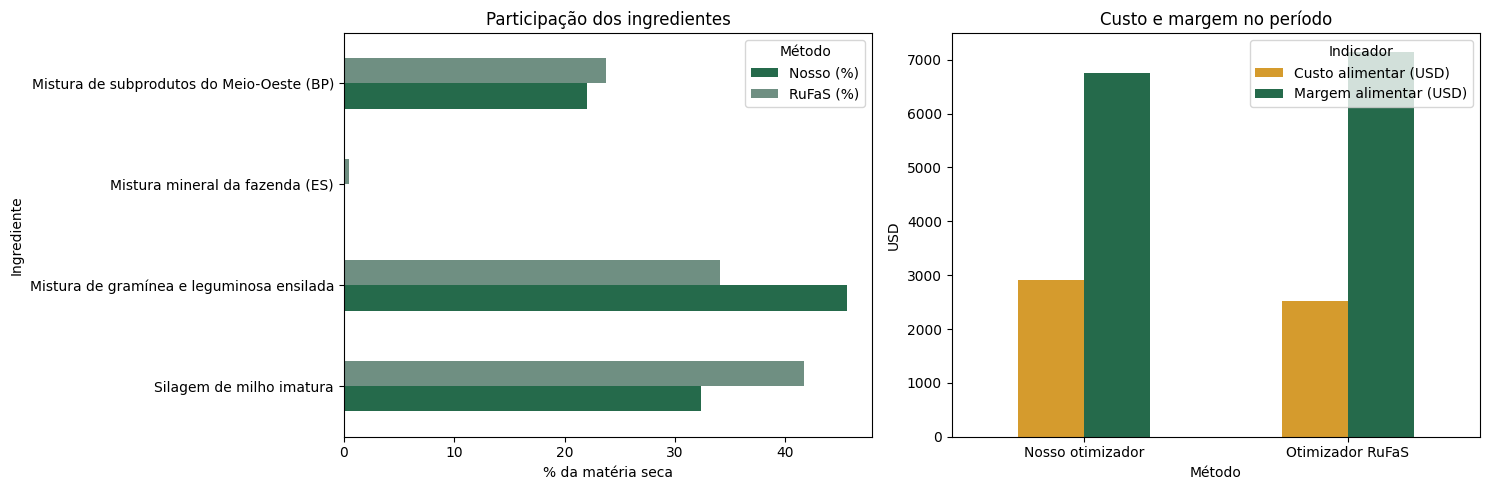

In [25]:
# BLOCO 1 — Avaliação econômica sob as mesmas premissas
custom_economics = calculate_economics(custom_result, custom_scenario)
rufas_economics = calculate_economics(rufas_result, rufas_scenario)
comparison = compare_scenarios({
    'Nosso otimizador': (custom_result, custom_economics),
    'Otimizador RuFaS': (rufas_result, rufas_economics),
}).rename(columns={
    'milk_kg': 'Leite total (kg)',
    'average_daily_milk_kg': 'Leite médio (kg/dia)',
    'feed_cost': 'Custo alimentar (USD)',
    'milk_revenue': 'Receita do leite (USD)',
    'margin_over_feed_cost': 'Margem alimentar (USD)',
}).rename_axis('Cenário')

# BLOCO 2 — Conversão complementar de massa para volume
milk_density = reference.economics.milk_density_kg_per_liter
comparison.insert(1, 'Leite total (L)', comparison['Leite total (kg)'] / milk_density)
comparison.insert(3, 'Leite médio (L/dia)', comparison['Leite médio (kg/dia)'] / milk_density)
show_table(
    comparison, 'Resultados produtivos e econômicos', hide_index=False,
    formatter=lambda value: format_pt_br(value, 2),
)

# BLOCO 3 — Gráficos de composição, custo e margem
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
composition_display.set_index('Ingrediente')[['Nosso (%)', 'RuFaS (%)']].plot.barh(
    ax=axes[0], color=['#256a4b', '#6f8f82']
)
axes[0].set_title('Participação dos ingredientes')
axes[0].set_xlabel('% da matéria seca')
axes[0].set_ylabel('Ingrediente')
axes[0].legend(title='Método')

comparison[['Custo alimentar (USD)', 'Margem alimentar (USD)']].plot.bar(
    ax=axes[1], color=['#d59b2d', '#256a4b']
)
axes[1].set_title('Custo e margem no período')
axes[1].set_xlabel('Método')
axes[1].set_ylabel('USD')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Indicador')
plt.tight_layout()